# Práctica: Clasificación de Imágenes mediante Modelos Pre-entrenados y Vision Transformers
## Inferencia Out-of-the-Box sobre ImageNet (CNNs vs. ViT)

**Cátedra:** Visión por Computadora —
**FICH-UNL (Santa Fe, Argentina)**

### **Objetivos del Trabajo Práctico**
1. **Comprender el alcance de los modelos pre-entrenados:** Evaluar la capacidad de generalización de arquitecturas convolucionales históricas (VGG16, ResNet50 e InceptionV3) entrenadas sobre el dataset ImageNet (1,000 clases).
2. **Analizar el pipeline de inferencia off-the-shelf:** Estudiar los requerimientos de preprocesamiento, escalado de dimensiones, disposición de canales (`[B, H, W, C]` vs. `[B, C, H, W]`) y decodificación de *logits* a probabilidades Softmax.
3. **Introducir la arquitectura Vision Transformer (ViT):** Explorar la aplicación de mecanismos de auto-atención (*Self-Attention*) en visión por computadora utilizando la librería Hugging Face `transformers`.
4. **Evaluar el comportamiento Out-of-Distribution (OOD):** Analizar la respuesta y vulnerabilidad de las redes convolucionales y transformers frente a conceptos ausentes en la distribución de entrenamiento (ejemplo: `choripan.jpg`).

---

## 📖 **Revisión teórica y fundamentos metodológicos**

En el desarrollo de la visión por computadora moderna, el entrenamiento de arquitecturas profundas desde cero representa un reto computacional considerable, requiriendo millones de imágenes anotadas y recursos de cómputo masivos. Gracias al esfuerzo de la comunidad científica y al proyecto **ImageNet** (ILSVRC), se ha consolidado el paradigma del uso de modelos **pre-entrenados *out-of-the-box*** (listos para usar sin reentrenamiento), permitiendo evaluar directamente la capacidad de abstracción y generalización de representaciones aprendidas previamente sobre 1,000 clases de objetos.

---


### 1. El Flujo Estándar de Inferencia en Redes Convolucionales (CNN)
Para utilizar cualquier modelo pre-entrenado en un marco de clasificación directa (como los disponibles en `tf.keras.applications`: VGG16, ResNet50 o InceptionV3), es indispensable cumplir con un pipeline de cuatro fases secuenciales:

1. **Instanciación:** Carga del modelo con sus pesos ajustados sobre ImageNet.
2. **Preprocesamiento Adaptativo (`preprocess_input`):** Acondicionamiento de la imagen de entrada. Las imágenes deben redimensionarse al tamaño espacial exacto que exige la arquitectura (ej. $224 \times 224$ o $299 \times 299$) y normalizar sus canales de color con la misma transformación estadística empleada durante su entrenamiento original.
3. **Inferencia por Lotes (`predict`):** Ajuste de las dimensiones del tensor para incluir el tamaño del lote (*batch size*), pasando de un tensor tridimensional $[H, W, C]$ a uno tetradimensional $[B, H, W, C]$ (donde $B=1$ para una única imagen).
4. **Decodificación de Predicciones (`decode_predictions`):** Conversión del vector de salida de 1,000 probabilidades (obtenido mediante la función *Softmax*) en etiquetas legibles junto con su índice y porcentaje de confianza.

---

### 2. De Convoluciones a Atención Global: Vision Transformers (ViT)
Mientras que las CNNs procesan la información de manera local aprovechando la invarianza espacial mediante filtros deslizantes, el **Vision Transformer (ViT)** (introducido por Google en 2020) traslada el éxito de la arquitectura *Transformer* del procesamiento del lenguaje natural a la visión.

* **Parches como Palabras:** La imagen se fragmenta en parches no superpuestos de $16 \times 16$ píxeles, los cuales se aplanan y proyectan como si fuesen una secuencia de "tokens" o palabras.
* **Auto-atención (*Self-Attention*):** Permite relacionar parches distantes entre sí desde la primera capa, capturando dependencias globales sin la restricción del campo receptivo acotado de las convoluciones.
* **Paradigma Hugging Face (`transformers`):** La implementación con bibliotecas basadas en PyTorch mantiene una equivalencia conceptual directa con Keras, aunque con diferencias clave de formato (disposición de canales `[B, C, H, W]` en lugar de `[B, H, W, C]`) y el uso de *processors* (`ViTImageProcessor`) para el escalado.

---

### 3. Alcance, Sesgo de Espacio Cerrado e Introducción a Transfer Learning
Aunque el uso de modelos *out-of-the-box* demuestra un rendimiento impresionante ante categorías estándar, presenta un límite conceptual crítico conocido como **clasificación en mundo cerrado**:

* **Entradas Fuera de Distribución (OOD):** Si el modelo recibe una imagen cuya clase no forma parte de las 1,000 categorías de ImageNet (por ejemplo, elementos regionales o gastronómicos locales como un *choripán*), la función *Softmax* forzará la asignación de probabilidades elevadas a las clases conceptual o visualmente más cercanas dentro del vocabulario que conoce (como *hotdog* o *baguette*), imposibilitando expresar falta de certeza.
* **Hacia la Transferencia de Aprendizaje (*Transfer Learning*):** Esta limitación motiva la necesidad de ir más allá del uso *out-of-the-box*. Cuando se requiere clasificar objetos específicos de un dominio nuevo, se recurre a la **Transferencia de Aprendizaje**, reutilizando las capas internas del modelo pre-entrenado como extractoras de características y reentrenando únicamente las capas clasificadoras finales con un nuevo conjunto de datos.

---

### 📚 **Lecturas Sugeridas (Conceptuales y Divulgativas)**

- [A Gentle Introduction to Transfer Learning for Deep Learning (Machine Learning Mastery)](https://machinelearningmastery.com/transfer-learning-for-deep-learning/)  
  *Un artículo de lectura ágil que explica sin tecnicismos excesivos qué es la transferencia de aprendizaje, por qué reutilizamos modelos pre-entrenados y cuándo conviene usar un modelo tal como viene o ajustarlo.*

- [Understanding Vision Transformers: A Beginner-Friendly Guide (Medium)](https://medium.com/@omerkurudatasc/understanding-vision-transformers-a-beginner-friendly-guide-c7948045f5a6)  
  *Una guía conceptual visual que explica paso a paso cómo una imagen se convierte en "parches" y cómo la auto-atención revolucionó la visión por computadora frente a las CNNs tradicionales.*

- [A Gentle Introduction to Softmax for Machine Learning (Machine Learning Mastery)](https://machinelearningmastery.com/softmax-activation-function-with-python/)  
  *Una explicación muy clara sobre la función Softmax, ideal para comprender intuitivamente por qué los modelos fuerzan porcentajes de probabilidad elevados incluso con imágenes que nunca antes han visto.*

---

## Carga de Librerías Iniciales

In [1]:
# Importar librerías fundamentales
import os
import glob
from zipfile import ZipFile
from urllib.request import urlretrieve

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image

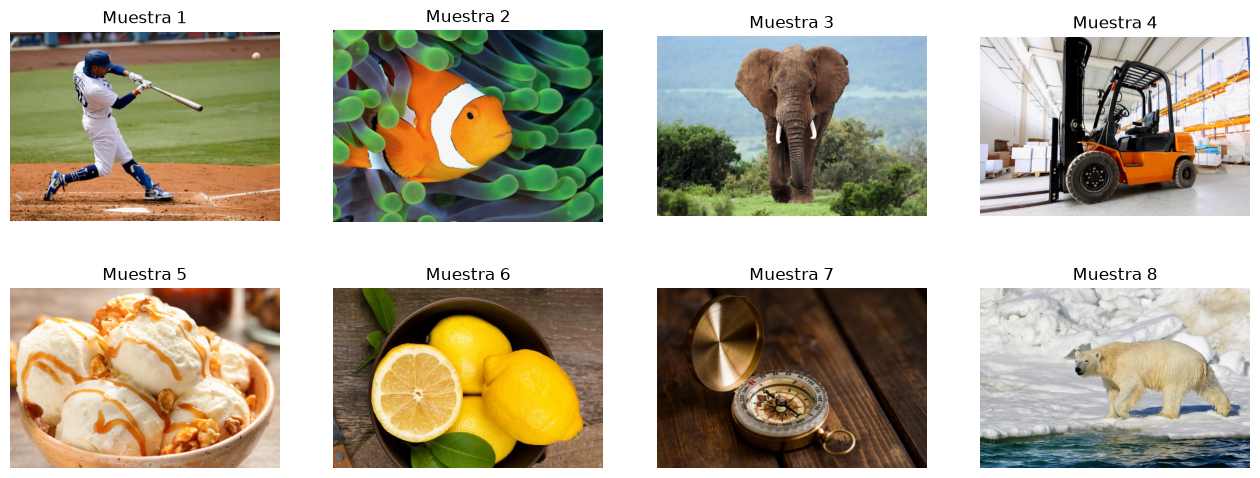

In [3]:
# Función para descargar y extraer imágenes de muestra
def download_and_unzip(url, save_path):
    print("Descargando y extrayendo recursos de prueba...", end="")
    urlretrieve(url, save_path)
    try:
        with ZipFile(save_path) as z:
            z.extractall(os.path.split(save_path)[0])
        print("Listo.")
    except Exception as e:
        print("\nError al extraer el archivo ZIP:", e)

URL = r"https://www.dropbox.com/s/8srx6xdjt9me3do/TF-Keras-Bootcamp-NB07-assets.zip?dl=1"
asset_zip_path = os.path.join(os.getcwd(), "TF-Keras-Bootcamp-NB07-assets.zip")

if not os.path.exists(asset_zip_path):
    download_and_unzip(URL, asset_zip_path)

# Obtener y listar rutas de imágenes
image_paths = sorted(glob.glob("images" + os.sep + "*.png"))

# Mostrar dataset de muestra
plt.figure(figsize=(16, 6))
for idx, image_path in enumerate(image_paths):
    image = plt.imread(image_path)
    plt.subplot(2, 4, idx + 1)
    plt.imshow(image)
    plt.title(f"Muestra {idx+1}")
    plt.axis('off')
plt.show()

## **Ejercicio 1: Fundamentos de ImageNet y Clasificación con Redes Convolucionales (CNN)**

En este ejercicio utilizaremos modelos convolucionales pre-entrenados en el desafío **ILSVRC** (ImageNet Large Scale Visual Recognition Challenge) para clasificar imágenes en una de las 1,000 categorías predefinidas.

El flujo de trabajo estándar en Keras consta de 4 etapas esenciales:
1. **Carga del modelo pre-entrenado:** Instanciación con pesos `'imagenet'`.
2. **Preprocesamiento:** Redimensionado y normalización según la arquitectura (`preprocess_input`).
3. **Inferencia:** Paso hacia adelante (*Forward pass*) mediante `.predict()` con dimensión de lote agregada (`[B, H, W, C]`).
4. **Postprocesamiento:** Decodificación de las top-k predicciones mediante `decode_predictions`.

In [2]:
# Instanciar arquitecturas convolucionales pre-entrenadas
model_vgg16 = tf.keras.applications.vgg16.VGG16(weights='imagenet')
model_resnet50 = tf.keras.applications.resnet50.ResNet50(weights='imagenet')
model_inception_v3 = tf.keras.applications.inception_v3.InceptionV3(weights='imagenet')

print(f"VGG16 Input Shape: {model_vgg16.input_shape}")
print(f"ResNet50 Input Shape: {model_resnet50.input_shape}")
print(f"InceptionV3 Input Shape: {model_inception_v3.input_shape}")

96112376/96112376 ━━━━━━━━━━━━━━━━━━━━ 20s 0us/step
VGG16 Input Shape: (None, 224, 224, 3)
ResNet50 Input Shape: (None, 224, 224, 3)
InceptionV3 Input Shape: (None, 299, 299, 3)


In [4]:
# Función auxiliar para procesamiento por lotes en Keras
def process_images(model, image_paths, size, preprocess_fn, display_top_k=False, top_k=2):
    plt.figure(figsize=(20, 7))
    for idx, image_path in enumerate(image_paths):
        # 1. Leer y decodificar la imagen
        tf_image = tf.io.read_file(image_path)
        decoded_image = tf.image.decode_image(tf_image, channels=3)

        # 2. Redimensionar al tamaño esperado por la red
        image_resized = tf.image.resize(decoded_image, size)

        # 3. Expandir dimensión de lote [1, H, W, C]
        image_batch = tf.expand_dims(image_resized, axis=0)

        # 4. Aplicar preprocesamiento específico
        image_preprocessed = preprocess_fn(image_batch)

        # 5. Inferencia
        preds = model.predict(image_preprocessed, verbose=0)

        # 6. Decodificación de predicciones
        decoded_preds = tf.keras.applications.imagenet_utils.decode_predictions(preds, top=top_k)[0]

        if display_top_k:
            print(f"\n--- Muestra: {os.path.basename(image_path)} ---")
            for jdx in range(top_k):
                print(f"Top {jdx+1}: {decoded_preds[jdx][1]:25} Probabilidad: {decoded_preds[jdx][2]*100:.2f}%")

        plt.subplot(2, 4, idx + 1)
        plt.imshow(decoded_image.numpy().astype("uint8"))
        plt.axis('off')
        top_label = decoded_preds[0][1]
        top_score = decoded_preds[0][2] * 100
        plt.title(f"{top_label}\n({top_score:.2f}%)", fontsize=12)
    plt.tight_layout()
    plt.show()

=== Evaluación con VGG16 ===
35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


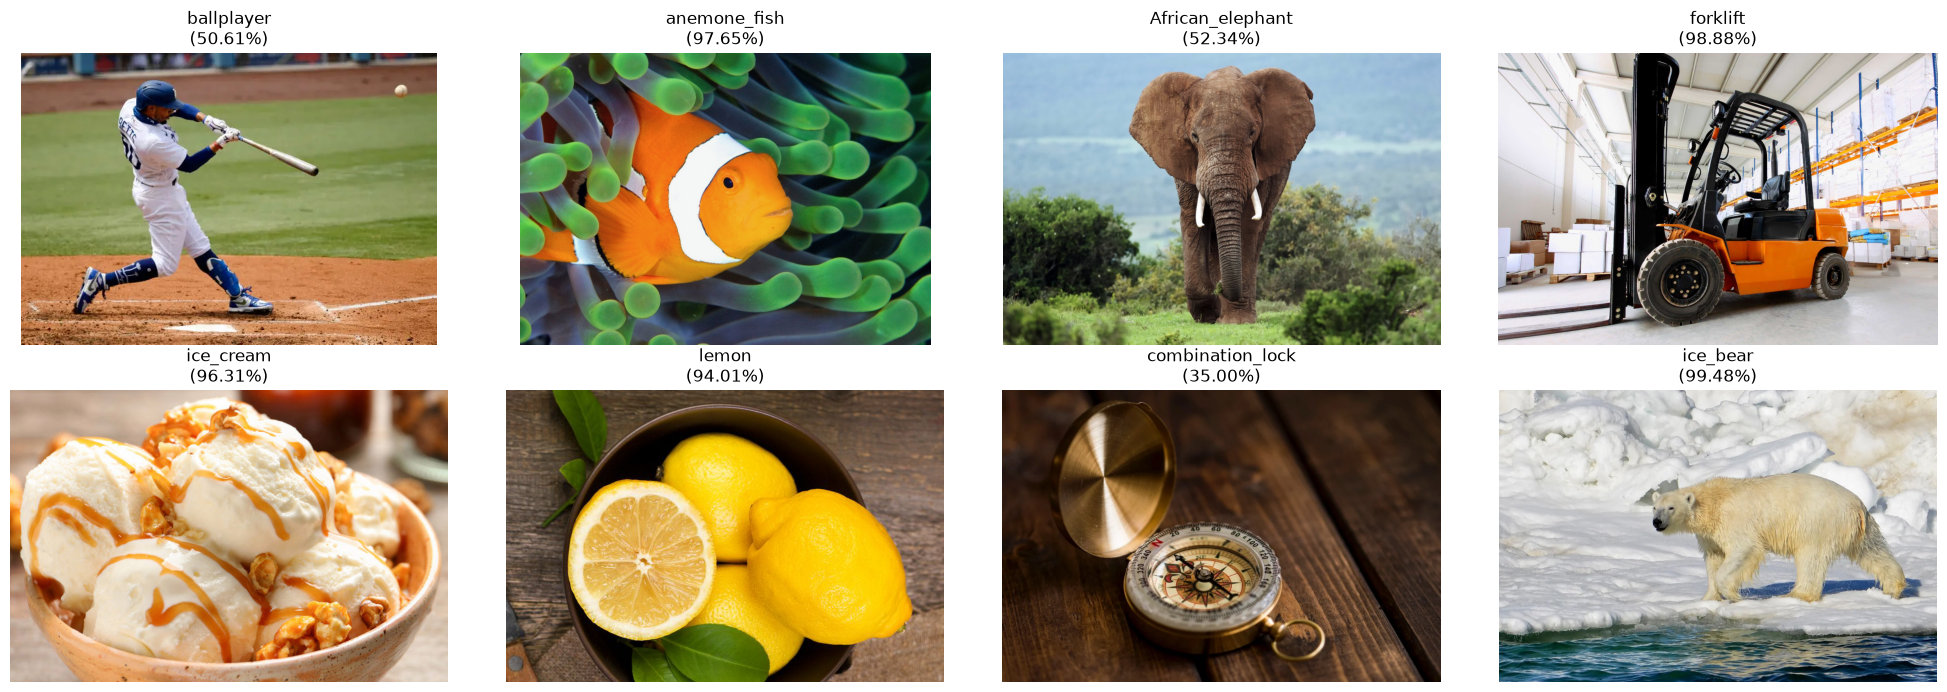




=== Evaluación con ResNet50 ===


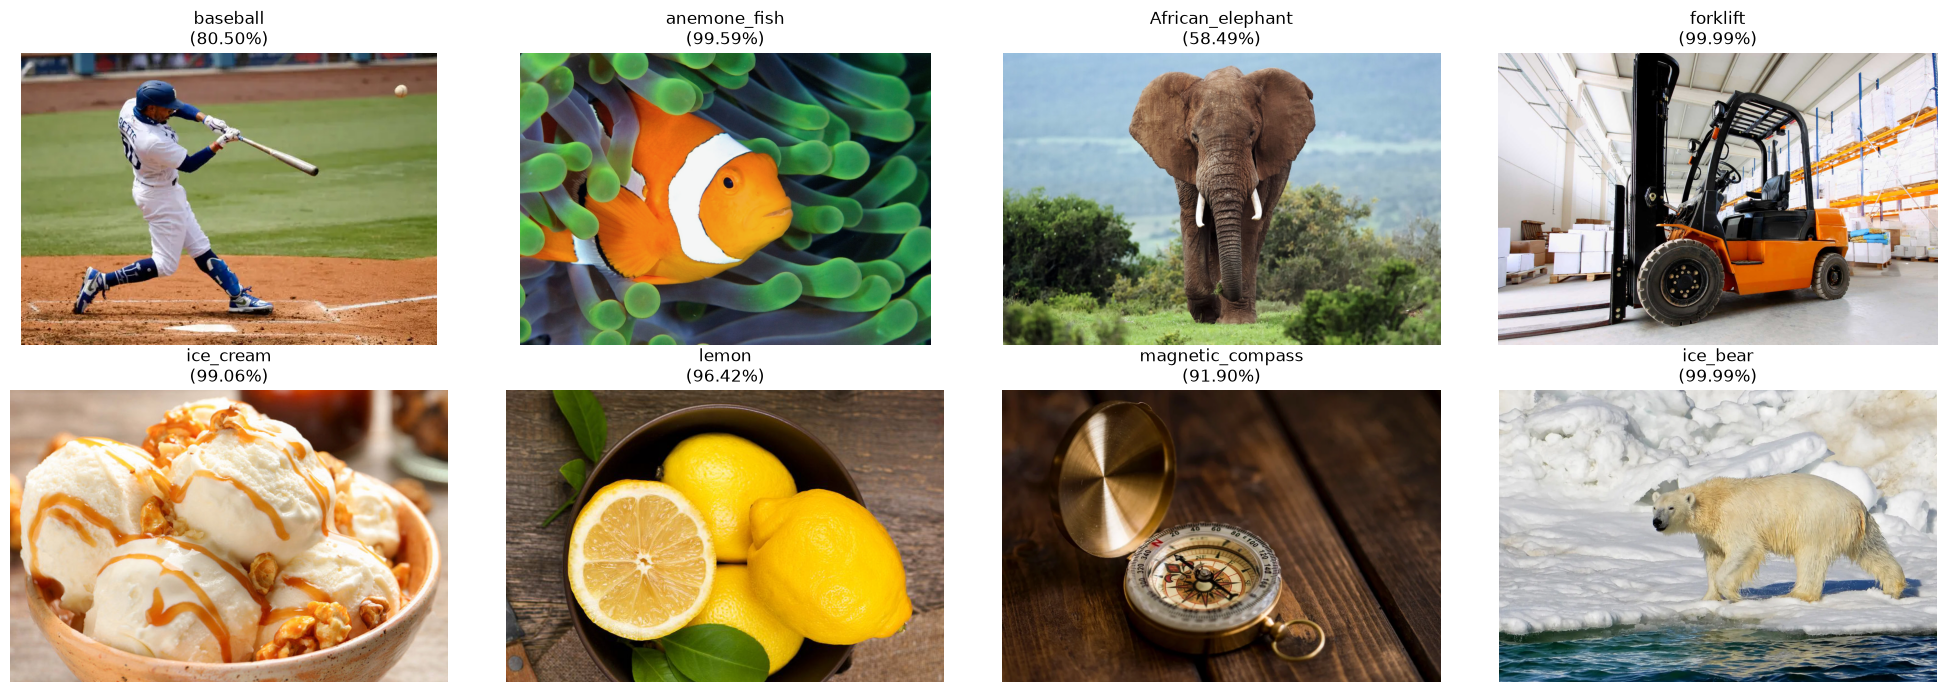




=== Evaluación con InceptionV3 (Top 2) ===

--- Muestra: baseball-player.png ---
Top 1: ballplayer                Probabilidad: 69.22%
Top 2: baseball                  Probabilidad: 30.62%

--- Muestra: clown-fish.png ---
Top 1: anemone_fish              Probabilidad: 92.48%
Top 2: sea_anemone               Probabilidad: 2.61%

--- Muestra: elephant.png ---
Top 1: African_elephant          Probabilidad: 89.94%
Top 2: tusker                    Probabilidad: 7.94%

--- Muestra: forklift.png ---
Top 1: forklift                  Probabilidad: 98.95%
Top 2: golfcart                  Probabilidad: 0.07%

--- Muestra: ice-cream.png ---
Top 1: ice_cream                 Probabilidad: 99.60%
Top 2: cradle                    Probabilidad: 0.08%

--- Muestra: lemons.png ---
Top 1: lemon                     Probabilidad: 97.06%
Top 2: orange                    Probabilidad: 2.12%

--- Muestra: magnetic-compass.png ---
Top 1: magnetic_compass          Probabilidad: 97.08%
Top 2: stopwatch        

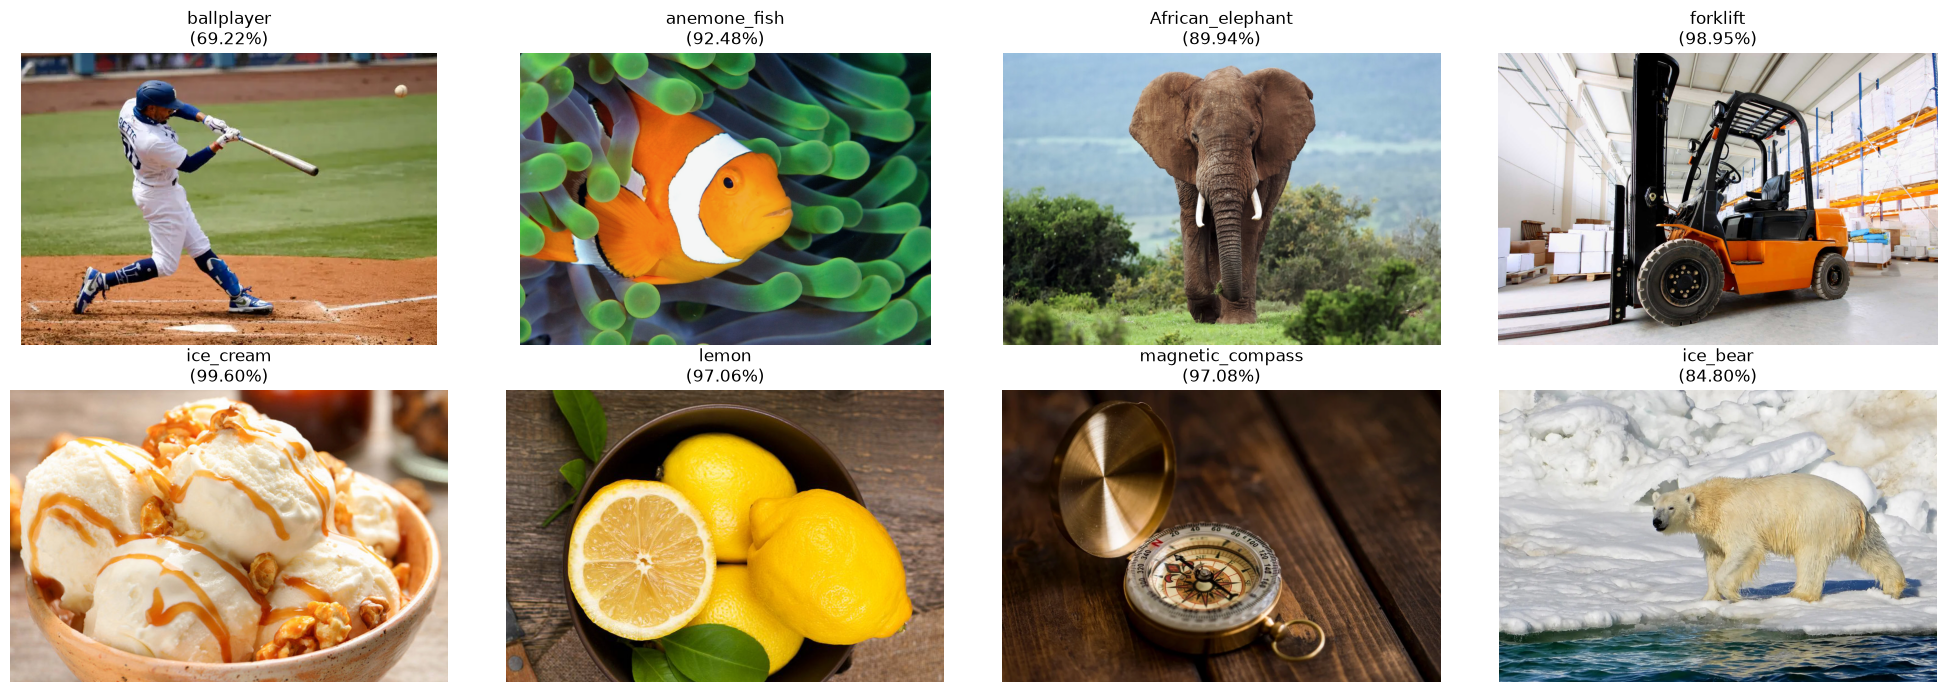

In [5]:
# Evaluación sobre VGG16
print("=== Evaluación con VGG16 ===")
process_images(model_vgg16, image_paths, (224, 224), tf.keras.applications.vgg16.preprocess_input)
print("\n\n")

# Evaluación sobre ResNet50
print("=== Evaluación con ResNet50 ===")
process_images(model_resnet50, image_paths, (224, 224), tf.keras.applications.resnet50.preprocess_input)
print("\n\n")

# Evaluación sobre InceptionV3 mostrando Top-2
print("=== Evaluación con InceptionV3 (Top 2) ===")
process_images(model_inception_v3, image_paths, (299, 299), tf.keras.applications.inception_v3.preprocess_input, display_top_k=True, top_k=2)

### 💡 Reflexión - Ejercicio 1: Arquitecturas Convolucionales y Preprocesamiento

1. **Estrategias de Preprocesamiento:**
  * Investiga cómo difiere la función `preprocess_input` entre **VGG16** (conversión BGR y centrado de media por canal) e **InceptionV3** (escalado a $[-1, 1]$).
  * ¿Por qué fallaría drásticamente la inferencia de InceptionV3 si le entregáramos píxeles en el rango $[0, 255]$ sin transformar?

2. **Evolución Arquitectónica:**
  * **VGG16** posee $\approx 138$ millones de parámetros, mientras que **ResNet50** posee $\approx 25.5$ millones. ¿Qué innovación estructural (*Residual Blocks / Skip Connections*) permite a ResNet ser más profunda, más precisa y significativamente más liviana en parámetros?

3. **Invariance y Modos de Redimensionamiento:**
  * Al forzar una imagen de relación de aspecto arbitraria a una resolución cuadrada ($224 \times 224$ o $299 \times 299$), ¿qué ocurre con la distorsión geométrica y cómo puede afectar las activaciones de las primeras capas convolucionales?

**Enlaces y Lecturas Sugeridas:**
- [ImageNet Large Scale Visual Recognition Challenge (Russakovsky et al., 2015)](https://arxiv.org/abs/1409.0575)
- [Deep Residual Learning for Image Recognition (He et al., 2016)](https://arxiv.org/abs/1512.03385)
- [TensorFlow Keras Applications Documentation](https://www.tensorflow.org/api_docs/python/tf/keras/applications)

---

## **Ejercicio 2: Paradigma Vision Transformer (ViT) y Hugging Face 🤗**

En esta sección exploraremos el modelo **Vision Transformer (ViT)** (`google/vit-base-patch16-224`). A diferencia de las CNNs, ViT fragmenta la imagen de entrada en parches no superpuestos de $16 \times 16$ píxeles, proyecta linealmente cada parche a un vector de embedding y procesa la secuencia utilizando bloques de **Multi-Head Self-Attention**.

Compararemos la API de Keras con la ecosistema de Hugging Face (`transformers` + `PyTorch`):

In [6]:

import torch
from transformers import ViTImageProcessor, ViTForImageClassification

# Cargar procesador de imágenes y arquitectura pre-entrenada
MODEL_NAME = 'google/vit-base-patch16-224'
feature_extractor = ViTImageProcessor.from_pretrained(MODEL_NAME)
model_vit = ViTForImageClassification.from_pretrained(MODEL_NAME)
model_vit.eval()  # Modo evaluación

print(f"Modelo ViT cargado correctamente. Número de parámetros: {sum(p.numel() for p in model_vit.parameters()):,}")

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

OSError: Can't load the model for 'google/vit-base-patch16-224'. If you were trying to load it from 'https://huggingface.co/models', make sure you don't have a local directory with the same name. Otherwise, make sure 'google/vit-base-patch16-224' is the correct path to a directory containing a file named pytorch_model.bin.

In [ ]:
# Definir función de inferencia para Vision Transformer
def vit_predict(image_path, top_k=5, show=False):
    image = Image.open(image_path).convert("RGB")

    # Preprocesamiento: Convierte a Tensor PyTorch en formato [B, C, H, W]
    inputs = feature_extractor(images=image, return_tensors="pt")

    with torch.no_grad():
        outputs = model_vit(**inputs)

    # Obtener logits y aplicar Softmax
    logits = outputs.logits
    probs = logits.softmax(-1)[0]

    top_results = probs.topk(top_k)
    preds = [(model_vit.config.id2label[idx.item()], prob.item())
             for prob, idx in zip(top_results.values, top_results.indices)]

    if show:
        print(f"\n--- Predicciones ViT para: {os.path.basename(image_path)} ---")
        for k, (label, p) in enumerate(preds):
            print(f"Top {k+1}: {label:45} {p*100:5.2f}%")

    return image, preds

In [ ]:
# Evaluar ViT sobre el conjunto de imágenes de prueba
plt.figure(figsize=(20, 7))
for idx, image_path in enumerate(image_paths):
    image, preds = vit_predict(image_path, top_k=1, show=False)
    label, prob = preds[0]

    plt.subplot(2, 4, idx + 1)
    plt.imshow(image)
    plt.axis('off')
    # Tomar la primera descripción de la clase en ImageNet
    short_label = label.split(',')[0]
    plt.title(f"{short_label}\n({prob*100:.2f}%)", fontsize=12)
plt.tight_layout()
plt.show()

### 💡 Reflexión - Ejercicio 2: Mecanismos de Atención y Representación de Imágenes

1. **Sesgo Inductivo (*Inductive Bias*):**
  * Las redes convolucionales asumen **localidad espacial** e **invariancia ante traslaciones** por construcción. ¿Por qué se dice que el Vision Transformer carece de este sesgo inductivo y qué consecuencia tiene esto respecto al volumen de datos necesario para entrenarlo desde cero?

2. **Manejo de Dimensiones y Canales:**
  * Compara la disposición de tensores entre Keras/TensorFlow (`[Lote, Alto, Ancho, Canales]`) y PyTorch/HuggingFace (`[Lote, Canales, Alto, Ancho]`). ¿Qué transformaciones de ejes realiza internamente el `ViTImageProcessor`?

3. **Interpretabilidad por Mapas de Atención:**
  * ¿A qué equivale la matriz de atención entre parches en ViT respecto a los campos receptivos de una CNN en las capas profundas?

**Enlaces y Lecturas Sugeridas:**
- [An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale (Dosovitskiy et al., 2020)](https://arxiv.org/abs/2010.11929)
- [Hugging Face Transformers - VisionTransformer Documentation](https://huggingface.co/docs/transformers/model_doc/vit)

---

## **Ejercicio 3: Evaluación de Inferencia Fuera de Distribución (OOD) y Experimentos Comparativos**

Los modelos pre-entrenados sobre ImageNet están acotados a asignar probabilidades sobre su espacio cerrado de 1,000 clases $Y \in \{0, \dots, 999\}$.

En este ejercicio evaluaremos el comportamiento del modelo ante un concepto gastronómico cultural no contemplado en ImageNet-1k: el **Choripán** (`choripan.jpg`).

In [ ]:
# Verificación y carga de la imagen OOD
# Descargue cualquier imagen de choripan y uselá !
CHORIPAN_PATH = "/content/choripan.jpg"

if not os.path.exists(CHORIPAN_PATH):
    try:
        from google.colab import files
        print("No se encontró 'choripan.jpg' en la raíz. Por favor sube la imagen:")
        uploaded = files.upload()
        nombre_subido = next(iter(uploaded))
        os.rename(nombre_subido, CHORIPAN_PATH)
    except ImportError:
        print("Entorno local detectado: asegúrate de colocar 'choripan.jpg' en el directorio de trabajo.")

print("Estado de la imagen 'choripan.jpg':", "Disponible" if os.path.exists(CHORIPAN_PATH) else "No encontrada")

No se encontró 'choripan.jpg' en la raíz. Por favor sube la imagen:


Saving choripan.jpg to choripan.jpg
Estado de la imagen 'choripan.jpg': Disponible


In [ ]:
# 1. Inferencia OOD con InceptionV3 (CNN)
print("==================================================")
print("  1. INFERENCIA OOD CON INCEPTION-V3 (CNN)")
print("==================================================")
process_images(model_inception_v3, [CHORIPAN_PATH], (299, 299),
               tf.keras.applications.inception_v3.preprocess_input,
               display_top_k=True, top_k=5)

# 2. Inferencia OOD con Vision Transformer (ViT)
print("==================================================")
print("  2. INFERENCIA OOD CON VISION TRANSFORMER (ViT)")
print("==================================================")
img_vit, preds_vit = vit_predict(CHORIPAN_PATH, top_k=5, show=True)

plt.figure(figsize=(6, 6))
plt.imshow(img_vit)
plt.title(f"OOD: choripan.jpg\nTop 1 ViT: {preds_vit[0][0].split(',')[0]} ({preds_vit[0][1]*100:.2f}%)")
plt.axis('off')
plt.show()

### 💡 Reflexión Guía - Ejercicio 3: Inferencia Out-of-Distribution (OOD) y Limitaciones

1. **Análisis de Clases Cercanas (Proxy Classes):**
  * Revisa los Top-5 arrojados tanto por **InceptionV3** como por **ViT** para `choripan.jpg` (ej. `hotdog`, `baguette`, `cheeseburger`). ¿Por qué la red asigna probabilidades elevadas a estas clases en lugar de distribuir la probabilidad de manera uniforme ($1/1000 = 0.1\%$) entre todas las categorías?

2. **Sobreconfianza en la Función Softmax:**
  * Explica matemáticamente cómo la función Softmax $\sigma(z)_i = \frac{e^{z_i}}{\sum_j e^{z_j}}$ fuerza a que la suma de salidas sea exactamente $1.0$, imposibilitando que la red exprese la respuesta: *"Esta imagen no pertenece a ninguna clase conocida"*.

3. **Estrategia para Resolver el Problema:**
  * Si quisiéramos adaptar esta red pre-entrenada para construir un sistema capaz de clasificar **Comidas Típicas Argentinas** (Choripán, Empanada, Milanesa, Asado):
    * ¿Por qué no es viable usar el modelo *out-of-the-box*?
    * Describe conceptualmente cómo la **Transferencia de Aprendizaje** (*Transfer Learning*) y el **Ajuste Fino** (*Fine-Tuning*) nos permiten reutilizar las capas extractoras de características reemplazando únicamente la capa clasificadora final.

**Enlaces y Lecturas Sugeridas:**
- [A Baseline for Detecting Out-of-Distribution Images in Neural Networks (Hendrycks & Gimpel, 2016)](https://arxiv.org/abs/1610.02136)
- [TensorFlow Guide: Transfer Learning and Fine-Tuning](https://www.tensorflow.org/tutorials/images/transfer_learning)
- [Hugging Face Fine-Tuning Multi-class Image Classification Models](https://huggingface.co/docs/transformers/tasks/image_classification)